# **One-Dimensional (1D)**

| Visualization                             | Example Data                                  | Why It Fits                                                                                                             |
| ----------------------------------------- | --------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------- |
| **Histogram**                             | Car Horsepower, Student Ages, Monthly Sales   | A single continuous numeric variable—shows how often values occur in intervals (bins).                                  |
| **Violin Plot**                           | Car MPG (miles per gallon), Employee Salaries | Displays the full shape of the distribution (peaks, tails, skewness). Ideal when you want to see density and variation. |
| **Box Plot**                              | Car Weight, Exam Scores                       | Summarizes spread (median, quartiles, outliers). Good for quick comparison between groups.                              |
| **Swarm Plot**                            | Car Horsepower by Origin (USA, Japan, Europe) | Shows every data point for a categorical variable (x) vs. a numeric value (y). Highlights clusters or gaps.             |
| **EDF (Empirical Distribution Function)** | Customer Age, Product Prices                  | Converts 1D data into a cumulative curve (what % of data ≤ X). Useful to compare distributions.                         |


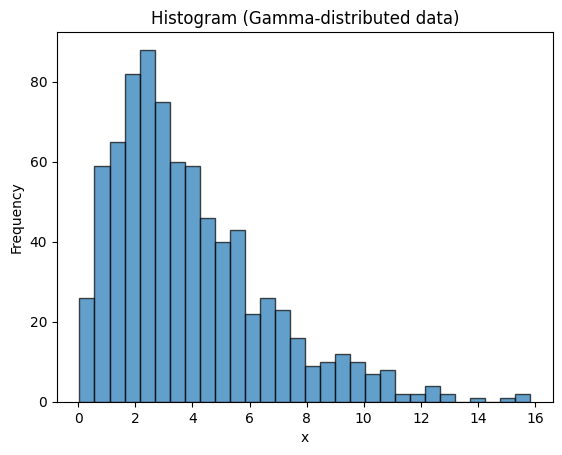

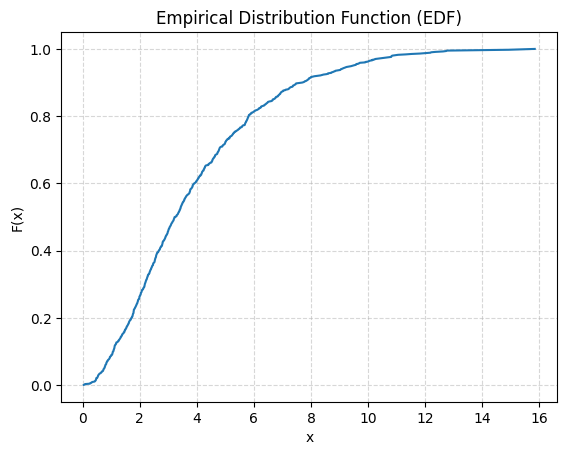

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
x = np.random.gamma(shape=2.0, scale=2.0, size=800)

plt.figure()
plt.hist(x, bins=30, edgecolor='black', alpha=0.7)
plt.title("Histogram (Gamma-distributed data)")
plt.xlabel("x"); plt.ylabel("Frequency")
plt.show()

x_sorted = np.sort(x)
edf = np.arange(1, len(x_sorted)+1) / len(x_sorted)

plt.figure()
plt.plot(x_sorted, edf)
plt.title("Empirical Distribution Function (EDF)")
plt.xlabel("x"); plt.ylabel("F(x)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


# **Numerical vs Categorical Data**

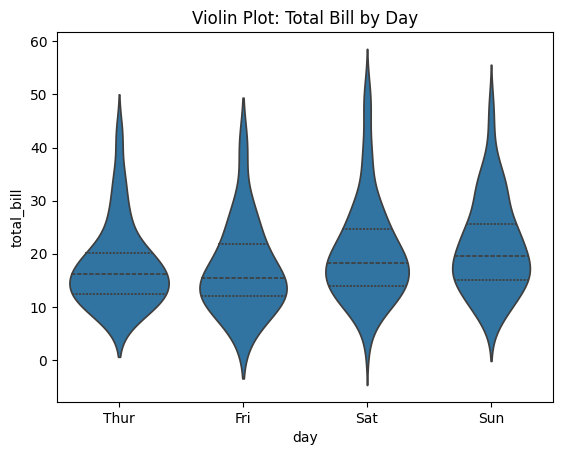

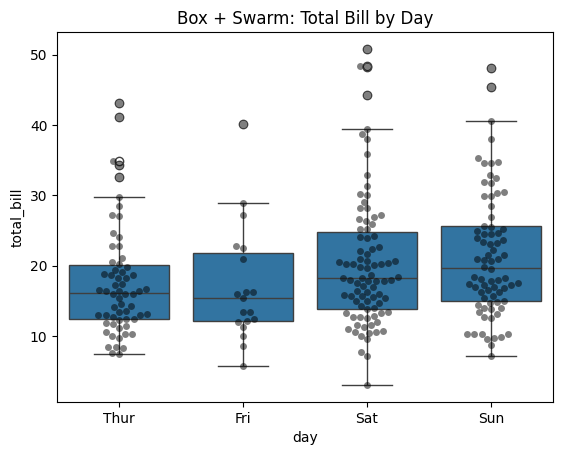

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")  # has columns: total_bill, tip, sex, smoker, day, time, size

plt.figure()
sns.violinplot(x="day", y="total_bill", data=df, inner="quartile")
plt.title("Violin Plot: Total Bill by Day")
plt.show()

plt.figure()
sns.boxplot(x="day", y="total_bill", data=df)
sns.swarmplot(x="day", y="total_bill", data=df, color="k", alpha=0.5)
plt.title("Box + Swarm: Total Bill by Day")
plt.show()


# **Two-Dimensional (2D)**

| Visualization    | Example Data                                                     | Why It Fits                                                                               |
| ---------------- | ---------------------------------------------------------------- | ----------------------------------------------------------------------------------------- |
| **Scatter Plot** | Horsepower (x) vs. MPG (y)                                       | Both numeric → shows correlation (strong, weak, negative). Each point = one car.          |
| **2D Histogram** | Horsepower vs. Weight                                            | Two numeric variables with many points → bins the space into coloured cells by frequency. |
| **Heat Map**     | Correlation matrix of numeric features (Horsepower, MPG, Weight) | A table of pairwise numeric relationships visualised by colour. Perfect for overviews.    |
| **Line Plot**    | Time (x) vs. Average MPG per Year (y)                            | Numeric variable that changes over time → shows trend.                                    |


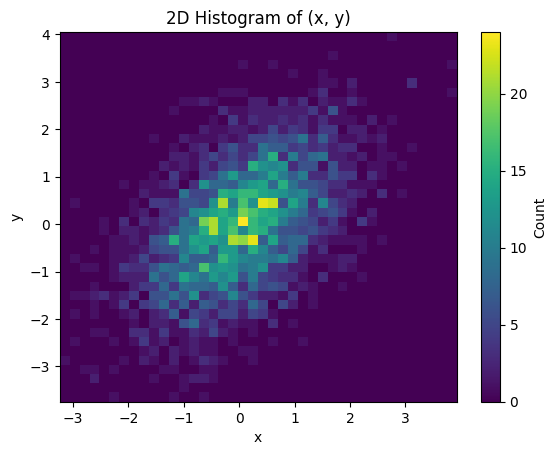

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
x = np.random.normal(0, 1.0, 3000)
y = 0.6*x + np.random.normal(0, 1.0, 3000)

plt.figure()
h = plt.hist2d(x, y, bins=40, cmap="viridis")
plt.colorbar(h[3], label="Count")
plt.title("2D Histogram of (x, y)")
plt.xlabel("x"); plt.ylabel("y")
plt.show()


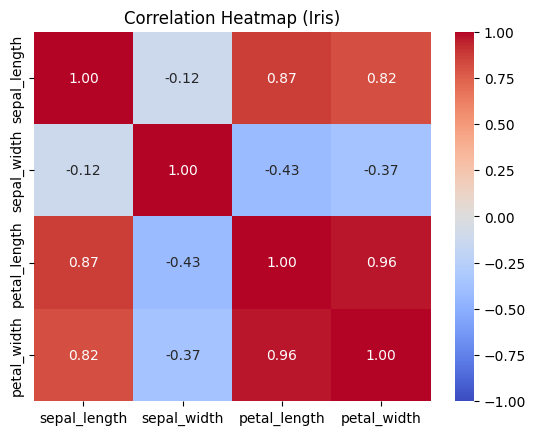

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("iris")
corr = df.drop(columns=["species"]).corr()

plt.figure()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Iris)")
plt.show()


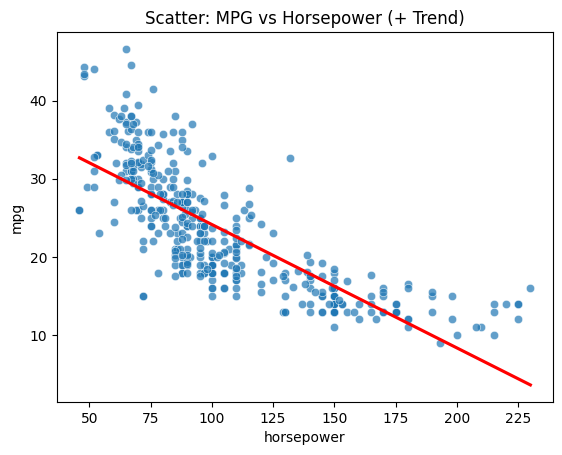

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("mpg").dropna(subset=["horsepower","mpg"])

plt.figure()
sns.scatterplot(data=df, x="horsepower", y="mpg", alpha=0.7)
sns.regplot(data=df, x="horsepower", y="mpg", scatter=False, ci=None, color="red")
plt.title("Scatter: MPG vs Horsepower (+ Trend)")
plt.show()


# **Three-Dimensional (3D)**

| Visualization       | Example Data                                           | Why It Fits                                                                     |
| ------------------- | ------------------------------------------------------ | ------------------------------------------------------------------------------- |
| **3D Scatter Plot** | X = Horsepower, Y = Weight, Z = MPG                    | Each car becomes one point in 3D space → helps spot multidimensional trends.    |
| **3D Surface Plot** | X = Horsepower, Y = Weight, Z = predicted MPG (f(x,y)) | Used for smooth continuous relationships (mathematical or regression surfaces). |
| **3D Bar Plot**     | Product Category × Quarter × Revenue                   | Good for comparing grouped values across two categorical axes and one numeric.  |


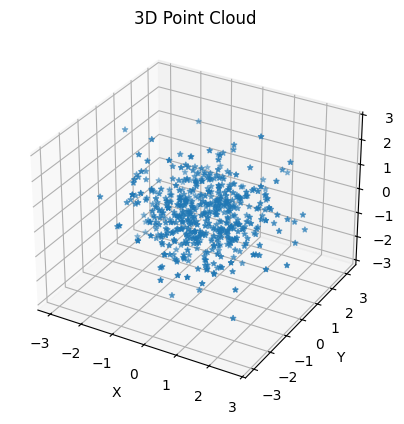

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

np.random.seed(0)
X = np.random.normal(0, 1, size=(500, 3))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:,0], X[:,1], X[:,2], marker='*', s=15)
ax.set_title("3D Point Cloud")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
plt.show()


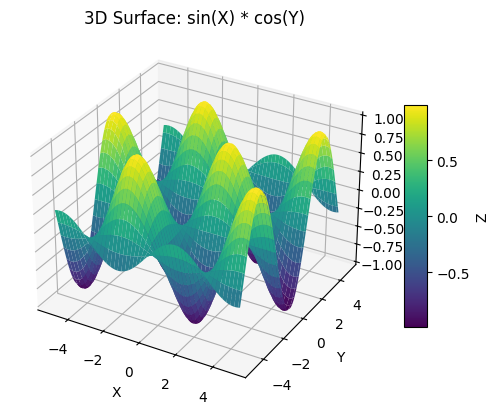

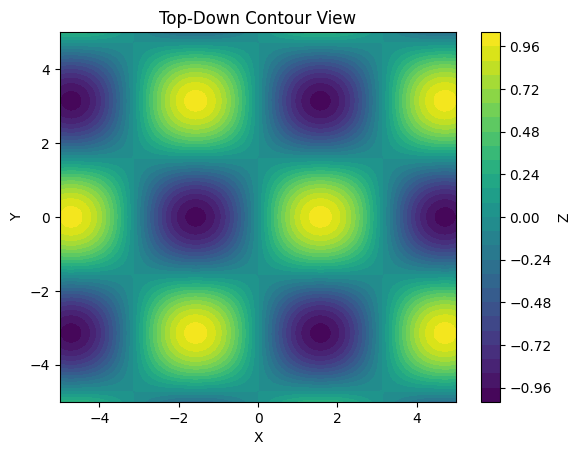

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = np.sin(X) * np.cos(Y)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, Z, cmap='viridis')
fig.colorbar(surf, shrink=0.6, aspect=10, label="Z")
ax.set_title("3D Surface: sin(X) * cos(Y)")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
plt.show()

fig = plt.figure()
ax = fig.add_subplot(111)
cs = ax.contourf(X, Y, Z, levels=30, cmap='viridis')
plt.colorbar(cs, label="Z")
plt.title("Top-Down Contour View")
plt.xlabel("X"); plt.ylabel("Y")
plt.show()


# **Dynamic (Time-Evolving)**

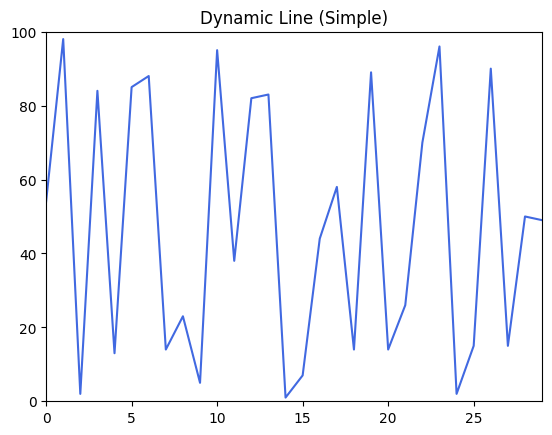

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import random


data = [0] * 30
fig, ax = plt.subplots()
(line,) = ax.plot(data, color='royalblue')
ax.set_ylim(0, 100)
ax.set_xlim(0, len(data)-1)
ax.set_title("Dynamic Line (Simple)")


def update(frame):
    data.pop(0)
    data.append(random.randint(0, 100))
    line.set_ydata(data)
    return (line,)

# Animate
ani = FuncAnimation(fig, update, frames=100, interval=100, blit=True)
HTML(ani.to_jshtml())



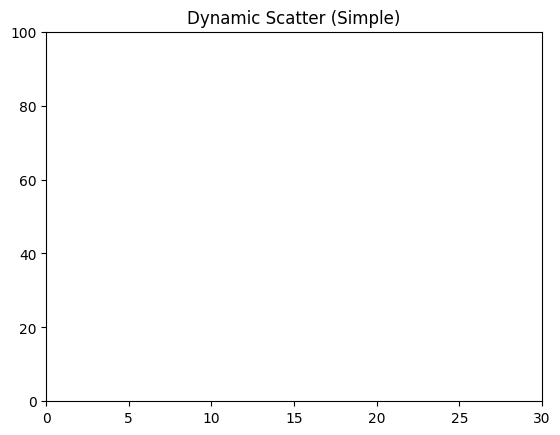

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import random
import numpy as np

x, y = [], []
fig, ax = plt.subplots()
sc = ax.scatter([], [], color='tomato', s=60)
ax.set_xlim(0, 30)
ax.set_ylim(0, 100)
ax.set_title("Dynamic Scatter (Simple)")

def update(frame):
    x.append(frame)
    y.append(random.randint(0, 100))
    if len(x) > 30:          # keep last 30 points
        x.pop(0); y.pop(0)
    sc.set_offsets(np.c_[x, y])
    return (sc,)

ani = FuncAnimation(fig, update, frames=120, interval=120, blit=True)
HTML(ani.to_jshtml())


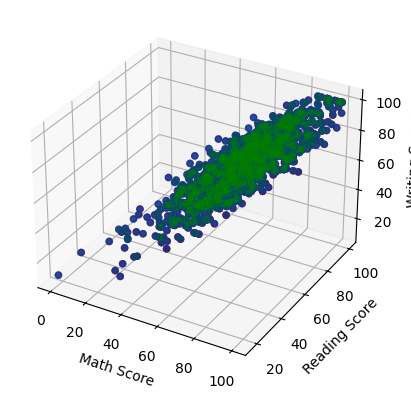

<Figure size 800x600 with 0 Axes>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("StudentsPerformance.csv")

math = df["math score"]
reading = df["reading score"]
writing = df["writing score"]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(math, reading, writing, c='red')
ax.scatter(math, reading, writing, c='blue', alpha=0.7)
ax.scatter(math, reading, writing, c='green', alpha=0.3)

ax.set_xlabel("Math Score")
ax.set_ylabel("Reading Score")
ax.set_zlabel("Writing Score")
fig = plt.figure(figsize=(8,6))

plt.show()
plt.show()


In [2]:
colors = []

for i in avg:
    if i < 50:
        colors.append("red")
    elif i < 70:
        colors.append("blue")
    else:
        colors.append("green")

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(math, reading, writing, c=colors)

ax.set_xlabel("Math Score")
ax.set_ylabel("Reading Score")
ax.set_zlabel("Writing Score")

plt.show()

NameError: name 'avg' is not defined

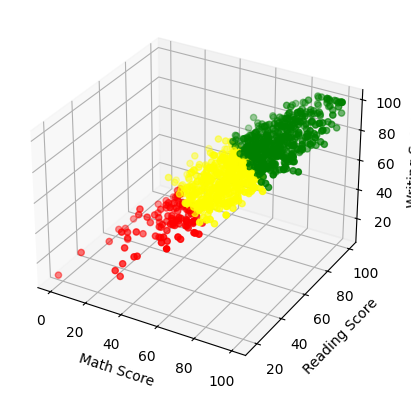

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("StudentsPerformance.csv")

math = df["math score"]
reading = df["reading score"]
writing = df["writing score"]

avg = (math + reading + writing) / 3

colors = []
for i in avg:
    if i < 50:
        colors.append("red")
    elif i < 70:
        colors.append("yellow")
    else:
        colors.append("green")

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(math, reading, writing, c=colors)

ax.set_xlabel("Math Score")
ax.set_ylabel("Reading Score")
ax.set_zlabel("Writing Score")

plt.show()

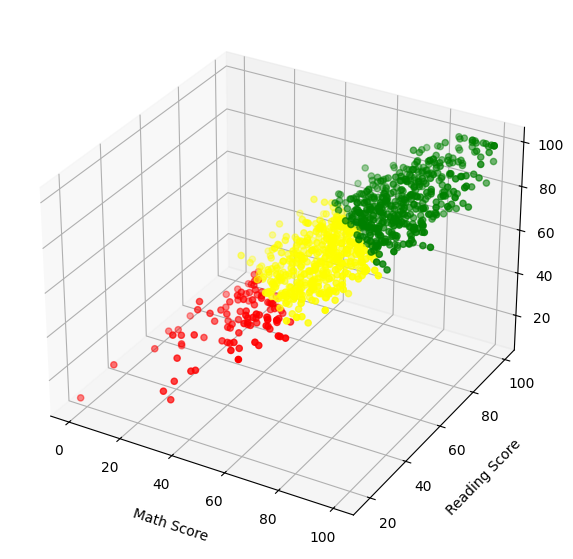

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("StudentsPerformance.csv")

math = df["math score"]
reading = df["reading score"]
writing = df["writing score"]

avg = (math + reading + writing) / 3

colors = []
for i in avg:
    if i < 50:
        colors.append("red")
    elif i < 70:
        colors.append("yellow")
    else:
        colors.append("green")

fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(math, reading, writing, c=colors)

ax.set_xlabel("Math Score", labelpad=10)
ax.set_ylabel("Reading Score", labelpad=10)
ax.set_zlabel("Writing Score", labelpad=20)

fig.subplots_adjust(right=0.85)

plt.show()